# 03 — Model Training

Two-stage transfer learning pipeline using **EfficientNetV2-S**:

**Stage 1 — EyePACS pre-training** (3-phase progressive unfreezing):
- **Phase 1**: Head-only with light augmentation (frozen backbone)
- **Phase 2**: Last block unfrozen (`blocks[-1:]`) with full augmentation + Mixup
- **Phase 3**: Full unfreeze with full augmentation + Mixup

Key features:
- Patient-level stratified splitting (no data leakage)
- Combined loss: Ordinal cross-entropy + Focal loss
- Exponential Moving Average (EMA)
- Cosine LR with warmup + discriminative LR
- Checkpointing on Quadratic Weighted Kappa (QWK)
- **AMP**: `Trainer` uses `config.AMP_DTYPE` (default **bfloat16** on CUDA when supported; else float16 + GradScaler). Override with env `DR_AMP_DTYPE=float16` if needed.

Recommended project flow: this notebook → `03b_aptos_finetuning.ipynb` → `04_evaluation.ipynb`. A JSON run manifest is merged under `outputs/logs/run_manifest.json`.


In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle scipy
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
config.ensure_dirs()


/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd
import torch

from src.augmentations import get_light_train_transforms, get_train_transforms, get_valid_transforms
from src.dataset import (
    compute_class_weights,
    create_dataloaders,
    load_and_split_dataframe,
    preprocess_images_to_cache,
)
from src.model import (
    ModelEMA,
    build_model,
    count_parameters,
    freeze_backbone,
    unfreeze_backbone,
)
from src.trainer import Trainer
from src.utils import get_device, log_gpu_memory, seed_everything, write_run_manifest

seed_everything()
device = get_device()
log_gpu_memory("Initial")

write_run_manifest(
    config.RUN_MANIFEST_PATH,
    {
        "stage": "eyepacs",
        "notebook": "03_training",
        "AMP_DTYPE": config.AMP_DTYPE,
        "MODEL_NAME": config.MODEL_NAME,
        "STAGE1_BATCH_SIZE": config.STAGE1_BATCH_SIZE,
        "PREPROCESSING_CACHE_VERSION": config.PREPROCESSING_CACHE_VERSION,
    },
    merge=True,
)


Using GPU: NVIDIA H200 (150.1 GB)
Initial | GPU Memory — Allocated: 0.00GB | Reserved: 0.00GB | Total: 150.1GB


## 1. Data Preparation


In [3]:
# Load and split EyePACS dataset (patient-level stratification)
train_df, valid_df, test_df = load_and_split_dataframe(dataset_name="eyepacs")

print(f'Train : {len(train_df):,} images  ({train_df["patient_id"].nunique():,} patients)')
print(f'Valid : {len(valid_df):,} images  ({valid_df["patient_id"].nunique():,} patients)')
print(f'Test  : {len(test_df):,} images  ({test_df["patient_id"].nunique():,} patients)')
print('\nTrain class distribution:')
print(train_df["level"].value_counts().sort_index())


Train : 24,574 images  (12,292 patients)
Valid : 5,267 images  (2,634 patients)
Test  : 5,267 images  (2,635 patients)

Train class distribution:
level
0    18059
1     1702
2     3707
3      613
4      493
Name: count, dtype: int64


## 2. Preprocessing Cache + DataLoaders

Images are preprocessed once (crop + CLAHE + Ben Graham at 384x384) and cached to disk.
`DRDataset` auto-detects the cache and reads directly from it (~6x speedup).

Two sets of loaders:
- `loaders_light`: light augmentation for Phase 1 (head-only)
- `loaders_heavy`: full augmentation for Phase 2/3 (fine-tuning)


In [4]:
# Build preprocessing cache (runs once, skips existing images)
print("Building/verifying preprocessed cache...")
preprocess_images_to_cache(train_df, dataset_name="eyepacs")
preprocess_images_to_cache(valid_df, dataset_name="eyepacs")
print("Cache ready.")

Building/verifying preprocessed cache...


2026-04-24 05:59:17 | src.dataset | INFO | Cache build complete: 24574 written, 0 skipped, 0 missing. Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-04-24 05:59:17 | src.dataset | INFO | Cache metadata mismatch detected in /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs; forcing refresh.
2026-04-24 06:01:10 | src.dataset | INFO | Cache build complete: 5267 written, 0 skipped, 0 missing. Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs


Cache ready.


In [4]:
# Transforms
light_tfm = get_light_train_transforms(config.IMG_SIZE)
heavy_tfm = get_train_transforms(config.IMG_SIZE)
valid_tfm = get_valid_transforms(config.IMG_SIZE)

# Phase 1 loaders: light augmentation
loaders_light = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    dataset_name="eyepacs",
    train_transform=light_tfm,
    valid_transform=valid_tfm,
    batch_size=config.STAGE1_BATCH_SIZE,
)

# Phase 2/3 loaders: full augmentation
loaders_heavy = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    dataset_name="eyepacs",
    train_transform=heavy_tfm,
    valid_transform=valid_tfm,
    batch_size=config.STAGE1_BATCH_SIZE,
)

print(f"Train batches (light): {len(loaders_light['train'])}")
print(f"Train batches (heavy): {len(loaders_heavy['train'])}")
print(f"Valid batches:         {len(loaders_light['valid'])}")


2026-04-24 06:26:56 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-04-24 06:26:56 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-04-24 06:26:56 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-04-24 06:26:56 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs


Train batches (light): 255
Train batches (heavy): 255
Valid batches:         55


## 3. Model + Class Weights


In [5]:
model = build_model(pretrained=True)
params = count_parameters(model)

print(f"Model: {config.MODEL_NAME}")
print(f"Input size: {config.IMG_SIZE}x{config.IMG_SIZE}")
print(f"Total parameters: {params['total']:,}")
print(f"Stochastic depth: {config.STOCHASTIC_DEPTH_RATE}")
print(f"Dropout rate: {config.DROPOUT_RATE}")
print("\nLoss: Combined (OrdinalCE + FocalLoss)")
print(f"  Focal gamma: {config.FOCAL_GAMMA}")
print(f"  Label smoothing: {config.LABEL_SMOOTHING}")
print(f"  Class-weighted: {config.USE_CLASS_WEIGHTED_LOSS}")
print(f"\nMixup: {config.USE_MIXUP} (alpha={config.MIXUP_ALPHA})")
print(f"  Class-conditional: {config.USE_CLASS_CONDITIONAL_MIXUP}")
print(f"\nEMA: {config.USE_EMA} (decay={config.EMA_DECAY})")


Model: tf_efficientnetv2_s.in21k_ft_in1k
Input size: 384x384
Total parameters: 21,169,238
Stochastic depth: 0.2
Dropout rate: 0.4

Loss: Combined (OrdinalCE + FocalLoss)
  Focal gamma: 2.0
  Label smoothing: 0.1
  Class-weighted: True

Mixup: True (alpha=0.4)
  Class-conditional: True

EMA: True (decay=0.9999)


In [6]:
# Class weights for loss function
class_weights = compute_class_weights(train_df["level"].values)
print("Class weights:")
for name, w in zip(config.CLASS_NAMES, class_weights, strict=True):
    print(f"  {name:20s}: {w:.4f}")


Class weights:
  No_DR               : 0.2722
  Mild                : 2.8877
  Moderate            : 1.3258
  Severe              : 8.0176
  Proliferative_DR    : 9.9692


## 4. Stage 1 — EyePACS Training

| Phase | Backbone | Augmentation | LR | WD | Epochs | Mixup |
|-------|----------|-------------|-----|-----|--------|-------|
| 1 | Frozen (head-only) | Light | 1e-3 | 1e-4 | 8 | No |
| 2 | blocks[-1:] (72%) | Full | 5e-5 | 1e-4 | 12 | Yes |
| 3 | Full unfreeze | Full | 1e-5 | 5e-4 | 15 | Yes |

Phase 2/3: head gets 10x the backbone LR (discriminative learning rates).


In [7]:
# Create EMA and Trainer
ema = ModelEMA(model) if config.USE_EMA else None

trainer = Trainer(
    model=model,
    device=device,
    class_weights=class_weights,
    ema=ema,
)

log_gpu_memory("After model init")


2026-04-24 06:27:04 | src.trainer | INFO | AMP dtype=torch.bfloat16 grad_scaler=False


After model init | GPU Memory — Allocated: 0.17GB | Reserved: 0.18GB | Total: 150.1GB


### Phase 1: Head-Only Training


In [8]:
freeze_backbone(model)
print(f"Phase 1 trainable: {count_parameters(model)}")

trainer.fit_phase(
    phase="s1_phase1",
    train_loader=loaders_light["train"],
    valid_loader=loaders_light["valid"],
    epochs=config.STAGE1_PHASE1_EPOCHS,
    lr=config.STAGE1_PHASE1_LR,
    weight_decay=config.STAGE1_PHASE1_WD,
    use_mixup=False,
)


2026-04-24 06:06:50 | src.trainer | INFO | 
2026-04-24 06:06:50 | src.trainer | INFO | Phase: S1_PHASE1 | Epochs: 8 | LR: 0.001 | Mixup: False | AMP: True (dtype=torch.bfloat16, scaler=False)
2026-04-24 06:06:50 | src.trainer | INFO | ============================================================


Phase 1 trainable: {'total': 21169238, 'trainable': 991750, 'frozen': 20177488, 'trainable_pct': 4.6848639521176905}


2026-04-24 06:07:54 | src.trainer | INFO | Epoch 01/8 (64s) | LR: 1.00e-03 | Train Loss: 2.8501 Acc: 0.1821 QWK: 0.1819 | Val Loss: 1.4083 Acc: 0.7152 QWK: 0.0144
2026-04-24 06:07:54 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (QWK=0.0144)
2026-04-24 06:08:29 | src.trainer | INFO | Epoch 02/8 (35s) | LR: 9.62e-04 | Train Loss: 2.5388 Acc: 0.1805 QWK: 0.2126 | Val Loss: 1.3898 Acc: 0.7188 QWK: 0.0168
2026-04-24 06:08:29 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (QWK=0.0168)
2026-04-24 06:09:04 | src.trainer | INFO | Epoch 03/8 (35s) | LR: 8.54e-04 | Train Loss: 2.5449 Acc: 0.1814 QWK: 0.2200 | Val Loss: 1.3730 Acc: 0.7139 QWK: 0.0558
2026-04-24 06:09:05 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (QWK=0.0558

True

### Phase 2: Partial Unfreeze (Last Block)


In [9]:
trainer.load_best_checkpoint(phase="s1_phase1")
unfreeze_backbone(model, from_block=config.STAGE1_PHASE2_UNFREEZE)
print(f"Phase 2 trainable: {count_parameters(model)}")

trainer.fit_phase(
    phase="s1_phase2",
    train_loader=loaders_heavy["train"],
    valid_loader=loaders_heavy["valid"],
    epochs=config.STAGE1_PHASE2_EPOCHS,
    lr=config.STAGE1_PHASE2_LR,
    weight_decay=config.STAGE1_PHASE2_WD,
    warmup_epochs=2,
    use_mixup=config.USE_MIXUP,
)


2026-04-24 06:12:24 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (epoch 5, QWK=0.1404)
2026-04-24 06:12:24 | src.trainer | INFO | 
2026-04-24 06:12:24 | src.trainer | INFO | Phase: S1_PHASE2 | Epochs: 12 | LR: 5e-05 | Mixup: True | AMP: True (dtype=torch.bfloat16, scaler=False)
2026-04-24 06:12:24 | src.trainer | INFO | ============================================================


Phase 2 trainable: {'total': 21169238, 'trainable': 15783726, 'frozen': 5385512, 'trainable_pct': 74.55972671288404}


2026-04-24 06:13:04 | src.trainer | INFO | Epoch 01/12 (40s) | LR: 2.50e-05 | Train Loss: 2.3115 Acc: 0.1946 QWK: 0.2730 | Val Loss: 1.3450 Acc: 0.5145 QWK: 0.1586
2026-04-24 06:13:04 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase2.pth (QWK=0.1586)
2026-04-24 06:13:39 | src.trainer | INFO | Epoch 02/12 (35s) | LR: 5.00e-05 | Train Loss: 2.1863 Acc: 0.2154 QWK: 0.3384 | Val Loss: 1.3431 Acc: 0.4055 QWK: 0.1349
2026-04-24 06:14:14 | src.trainer | INFO | Epoch 03/12 (35s) | LR: 5.00e-05 | Train Loss: 2.1456 Acc: 0.2330 QWK: 0.3735 | Val Loss: 1.3424 Acc: 0.3030 QWK: 0.1029
2026-04-24 06:14:49 | src.trainer | INFO | Epoch 04/12 (35s) | LR: 4.88e-05 | Train Loss: 2.0573 Acc: 0.2390 QWK: 0.3888 | Val Loss: 1.3384 Acc: 0.2436 QWK: 0.0862
2026-04-24 06:15:25 | src.trainer | INFO | Epoch 05/12 (35s) | LR: 4.52e-05 | Train Loss: 2.0913 Acc: 0.2386 QWK: 0.3938 | Val Loss: 1.3366 Acc: 0.2003 QWK: 0.0703
2026-04-2

False

### Phase 3: Full Unfreeze


In [10]:
trainer.load_best_checkpoint(phase="s1_phase2")
unfreeze_backbone(model, from_block=None)
print(f"Phase 3 trainable: {count_parameters(model)}")

trainer.fit_phase(
    phase="s1_phase3",
    train_loader=loaders_heavy["train"],
    valid_loader=loaders_heavy["valid"],
    epochs=config.STAGE1_PHASE3_EPOCHS,
    lr=config.STAGE1_PHASE3_LR,
    weight_decay=config.STAGE1_PHASE3_WD,
    warmup_epochs=2,
    use_mixup=config.USE_MIXUP,
)


2026-04-24 06:17:36 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase2.pth (epoch 1, QWK=0.1586)
2026-04-24 06:17:36 | src.trainer | INFO | 
2026-04-24 06:17:36 | src.trainer | INFO | Phase: S1_PHASE3 | Epochs: 15 | LR: 1e-05 | Mixup: True | AMP: True (dtype=torch.bfloat16, scaler=False)
2026-04-24 06:17:36 | src.trainer | INFO | ============================================================


Phase 3 trainable: {'total': 21169238, 'trainable': 21015366, 'frozen': 153872, 'trainable_pct': 99.27313396920569}


2026-04-24 06:18:35 | src.trainer | INFO | Epoch 01/15 (59s) | LR: 5.00e-06 | Train Loss: 2.0759 Acc: 0.2194 QWK: 0.3649 | Val Loss: 1.3426 Acc: 0.4215 QWK: 0.1430
2026-04-24 06:18:36 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth (QWK=0.1430)
2026-04-24 06:19:22 | src.trainer | INFO | Epoch 02/15 (46s) | LR: 1.00e-05 | Train Loss: 2.0146 Acc: 0.2330 QWK: 0.3957 | Val Loss: 1.3424 Acc: 0.3446 QWK: 0.1163
2026-04-24 06:20:07 | src.trainer | INFO | Epoch 03/15 (45s) | LR: 1.00e-05 | Train Loss: 1.9152 Acc: 0.2534 QWK: 0.4456 | Val Loss: 1.3420 Acc: 0.2842 QWK: 0.1065
2026-04-24 06:20:53 | src.trainer | INFO | Epoch 04/15 (46s) | LR: 9.85e-06 | Train Loss: 1.8316 Acc: 0.2645 QWK: 0.4776 | Val Loss: 1.3410 Acc: 0.2381 QWK: 0.0949
2026-04-24 06:21:38 | src.trainer | INFO | Epoch 05/15 (45s) | LR: 9.43e-06 | Train Loss: 1.8085 Acc: 0.2689 QWK: 0.4864 | Val Loss: 1.3409 Acc: 0.2056 QWK: 0.0908
2026-04-2

False

## 5. Training Curves


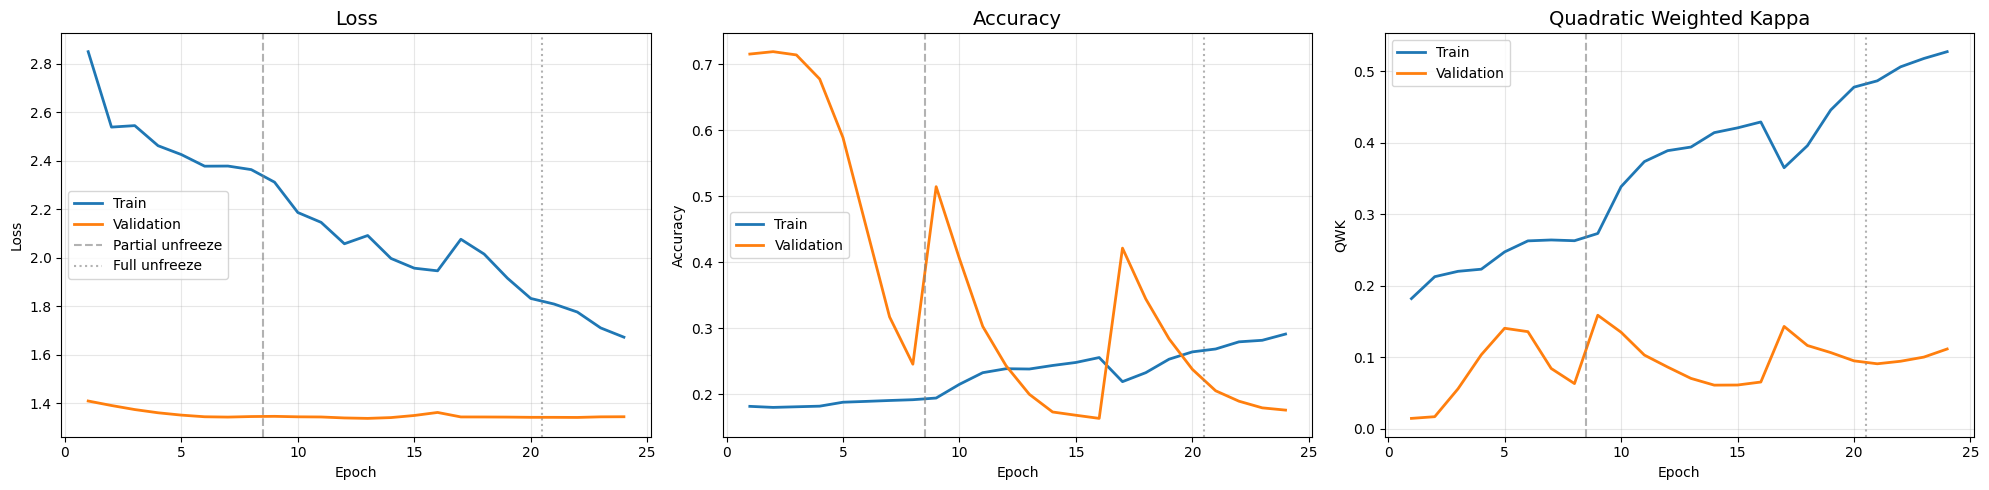

2026-04-24 06:24:00 | src.trainer | INFO | Training history saved to /teamspace/studios/this_studio/diabetic_retinopathy/outputs/logs/stage1_history.json


In [11]:
from src.evaluate import plot_training_curves

plot_training_curves(
    trainer.history,
    save_path=os.path.join(config.FIGURES_DIR, "stage1_training_curves.png"),
    phase_boundaries=[
        config.STAGE1_PHASE1_EPOCHS,
        config.STAGE1_PHASE1_EPOCHS + config.STAGE1_PHASE2_EPOCHS,
    ],
)

trainer.save_history(os.path.join(config.LOGS_DIR, "stage1_history.json"))


## 6. Quick Validation


In [8]:
from src.evaluate import compute_metrics, predict

trainer.load_best_checkpoint("s1_phase3")

if ema is not None:
    ema.apply(model)
    print("Applied EMA weights")

y_true, y_pred, y_proba = predict(model, loaders_heavy["valid"], device)
metrics = compute_metrics(y_true, y_pred, y_proba)

print(f"Validation QWK      : {metrics['qwk']:.4f}")
print(f"Validation Accuracy : {metrics['accuracy']:.4f}")
print(f"Validation ROC-AUC  : {metrics['roc_auc_weighted']:.4f}")
print(f"\n{metrics['classification_report_str']}")


2026-04-24 06:27:13 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth (epoch 1, QWK=0.1430)


Applied EMA weights


Validation QWK      : 0.1426
Validation Accuracy : 0.4236
Validation ROC-AUC  : 0.6229

                  precision    recall  f1-score   support

           No_DR     0.7953    0.4344    0.5619      3863
            Mild     0.0979    0.0610    0.0752       377
        Moderate     0.1800    0.6578    0.2826       786
          Severe     0.0000    0.0000    0.0000       133
Proliferative_DR     0.2653    0.1204    0.1656       108

        accuracy                         0.4236      5267
       macro avg     0.2677    0.2547    0.2170      5267
    weighted avg     0.6226    0.4236    0.4630      5267



/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter

## 7. Save Test Split


In [9]:
test_csv_path = os.path.join(config.OUTPUTS_DIR, "test_split_eyepacs.csv")
test_df.to_csv(test_csv_path, index=False)
print(f"Test split saved: {test_csv_path} ({len(test_df)} images)")


Test split saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/test_split_eyepacs.csv (5267 images)


## 8. ONNX Export

Export the best model to ONNX for production deployment.


In [11]:
from src.export import export_to_onnx

onnx_path = export_to_onnx(
    checkpoint_path=os.path.join(config.CHECKPOINTS_DIR, "best_model_s1_phase3.pth"),
)
print(f"\nONNX model exported to: {onnx_path}")


2026-04-24 06:28:51 | src.export | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth (epoch 0, QWK=0.14300838761529677)
/teamspace/studios/this_studio/diabetic_retinopathy/src/export.py:75: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0424 06:28:52.376000 127337 /system/conda/miniconda3/uv/cache/archive-v0/RqELNNhM_8pg54NqTun-s/torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please

[torch.onnx] Obtain model graph for `DRModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DRModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/system/conda/miniconda3/uv/python/cpython-3.12.11-linux-x86_64-gnu/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Failed to convert the model to the target version 17 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/onnx/version_con

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


2026-04-24 06:29:03 | src.export | INFO | ONNX validation passed (max diff: 1.07e-06)
2026-04-24 06:29:03 | src.export | INFO | ONNX model exported: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx (81.8 MB, opset 17)



ONNX model exported to: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx


## 9. Next Steps

Stage 1 (EyePACS pre-training) complete. Continue with:
- `python train_pipeline.py --stage2-only` for Stage 2 (APTOS fine-tuning)
- `04_evaluation.ipynb` for full evaluation
- `05_gradcam.ipynb` for explainability
